# Leaf Disease Detection (Potato & Tomato)
### Decision Tree vs Random Forest — Full Pipeline



## 1. Import Libraries

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, MinMaxScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("Libraries loaded.")

Libraries loaded.


## 2. Data Loading

In [2]:
# UPDATE this path to your dataset's location
CSV_PATH = r"C:\Users\user\OneDrive\Desktop\kaggle\leaf_disease_dataset.csv"

if not os.path.exists(CSV_PATH):
    raise FileNotFoundError(
        f"CSV not found at: {CSV_PATH}\n"
        "Update CSV_PATH above to the correct location of your dataset."
    )

df = pd.read_csv(CSV_PATH)
print("Shape:", df.shape)
print("\nColumns:", list(df.columns))
df.head()

Shape: (600, 9)

Columns: ['Leaf_Area', 'Mean_R', 'Mean_G', 'Mean_B', 'Texture', 'Moisture', 'Crop', 'Disease_Spots', 'Disease']


,Leaf_Area,Mean_R,Mean_G,Mean_B,Texture,Moisture,Crop,Disease_Spots,Disease
0,2512.33,118.25,122.59,78.75,0.670,49.58,Potato,9.82,Early_Blight
1,2586.59,135.51,132.67,64.56,0.602,49.16,Tomato,10.82,Early_Blight
2,1904.36,98.79,92.13,72.05,0.793,47.61,Tomato,27.56,Late_Blight
3,2426.93,113.36,131.44,79.24,0.386,53.17,Potato,1.20,Healthy
4,2028.83,116.17,129.83,79.82,0.669,52.45,Potato,11.05,Early_Blight


## 3. Data Exploration

In [3]:
print("Dataset Info:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nDisease Class Counts:")
print(df["Disease"].value_counts())

print("\nCrop Counts:")
print(df["Crop"].value_counts())

df.describe()

Dataset Info:
<class 'pandas.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Leaf_Area      600 non-null    float64
 1   Mean_R         600 non-null    float64
 2   Mean_G         600 non-null    float64
 3   Mean_B         600 non-null    float64
 4   Texture        600 non-null    float64
 5   Moisture       600 non-null    float64
 6   Crop           600 non-null    str    
 7   Disease_Spots  600 non-null    float64
 8   Disease        600 non-null    str    
dtypes: float64(7), str(2)
memory usage: 51.7 KB
None

Missing Values:
Leaf_Area        0
Mean_R           0
Mean_G           0
Mean_B           0
Texture          0
Moisture         0
Crop             0
Disease_Spots    0
Disease          0
dtype: int64

Duplicate Rows: 0

Disease Class Counts:
Disease
Early_Blight    200
Late_Blight     200
Healthy         200
Name: count, dtype: int64

Crop Counts:
Crop

,Leaf_Area,Mean_R,Mean_G,Mean_B,Texture,Moisture,Disease_Spots
count,600.000000,600.000000,600.000000,600.000000,600.000000,600.000000,600.000000
mean,2355.061317,109.926950,117.963650,69.303033,0.565310,59.622600,11.525667
std,374.354300,16.451656,23.434427,10.058695,0.213096,8.564532,8.016274
min,1234.970000,60.750000,59.940000,42.630000,0.143000,33.950000,0.000000
25%,2082.000000,99.370000,98.817500,62.815000,0.339750,53.530000,2.615000
50%,2358.460000,108.400000,117.340000,70.185000,0.614000,59.215000,12.230000
75%,2646.605000,121.345000,135.885000,76.090000,0.745000,65.852500,18.270000
max,3484.730000,157.320000,182.320000,95.590000,1.000000,83.720000,32.970000


## 4. Data Cleaning

In [4]:
# Remove duplicate rows
df = df.drop_duplicates()

# Clean column names
df.columns = df.columns.str.strip()

# Clean text columns
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()

# Fill missing numeric values with median
for col in df.select_dtypes(include=np.number).columns:
    df[col] = df[col].fillna(df[col].median())

# Fill missing categorical values with mode
for col in df.select_dtypes(include="object").columns:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].mode()[0])

print("Missing values after cleaning:")
print(df.isnull().sum())

print("\nFinal shape:", df.shape)
df.head()

Missing values after cleaning:
Leaf_Area        0
Mean_R           0
Mean_G           0
Mean_B           0
Texture          0
Moisture         0
Crop             0
Disease_Spots    0
Disease          0
dtype: int64

Final shape: (600, 9)


C:\Users\user\AppData\Local\Temp\ipykernel_33072\2162820912.py:8: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include="object").columns:
C:\Users\user\AppData\Local\Temp\ipykernel_33072\2162820912.py:16: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/m

,Leaf_Area,Mean_R,Mean_G,Mean_B,Texture,Moisture,Crop,Disease_Spots,Disease
0,2512.33,118.25,122.59,78.75,0.670,49.58,Potato,9.82,Early_Blight
1,2586.59,135.51,132.67,64.56,0.602,49.16,Tomato,10.82,Early_Blight
2,1904.36,98.79,92.13,72.05,0.793,47.61,Tomato,27.56,Late_Blight
3,2426.93,113.36,131.44,79.24,0.386,53.17,Potato,1.20,Healthy
4,2028.83,116.17,129.83,79.82,0.669,52.45,Potato,11.05,Early_Blight


## 5. Visualization

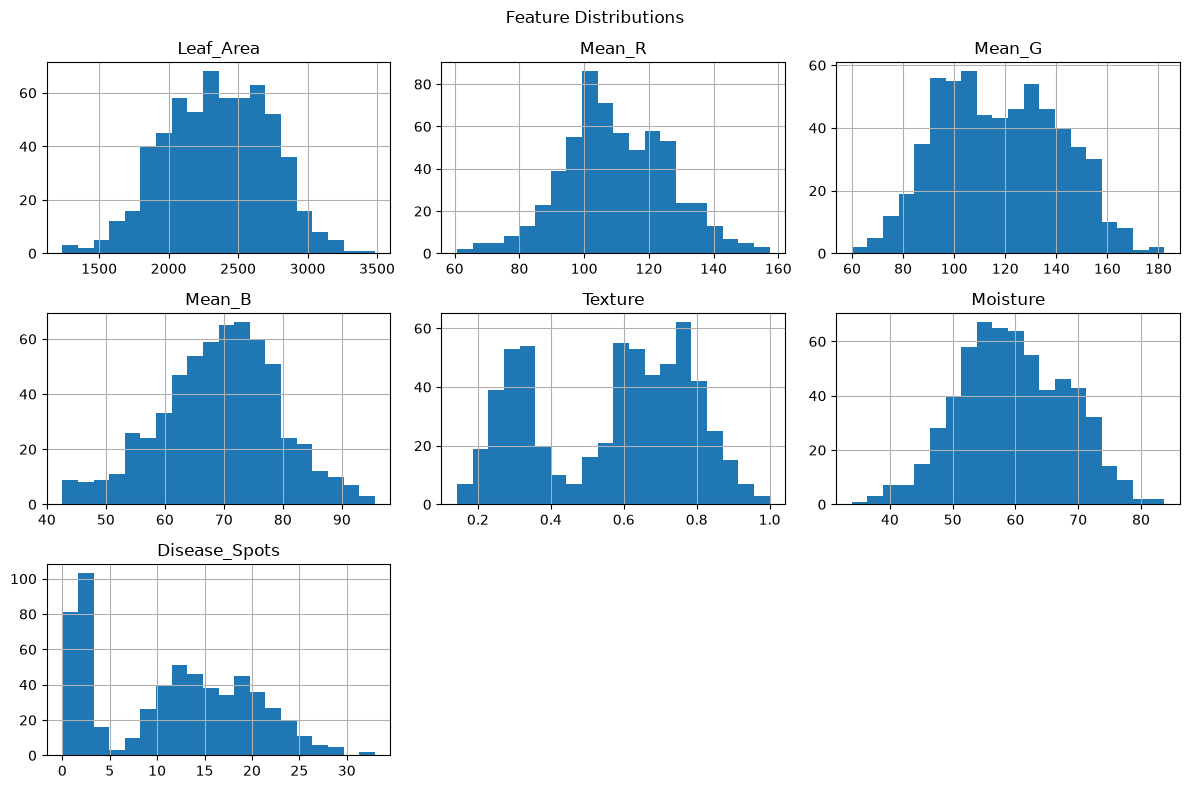

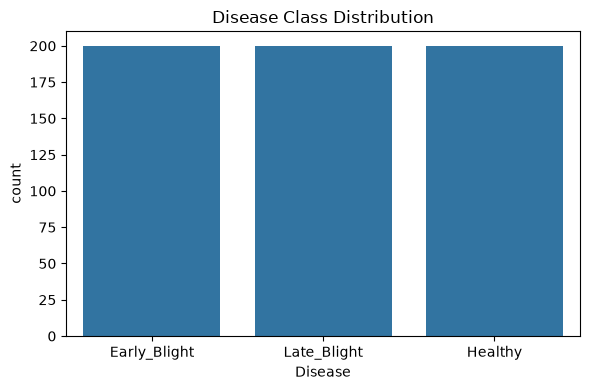

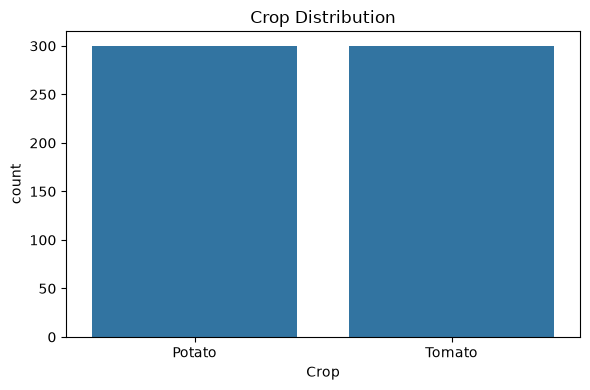

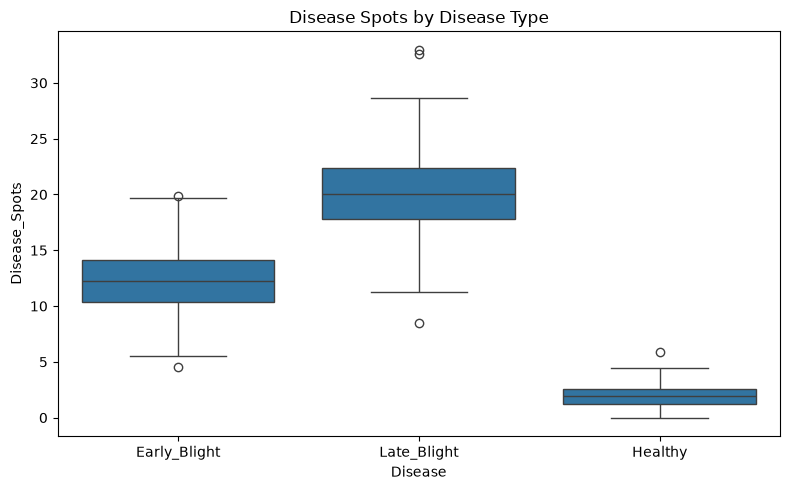

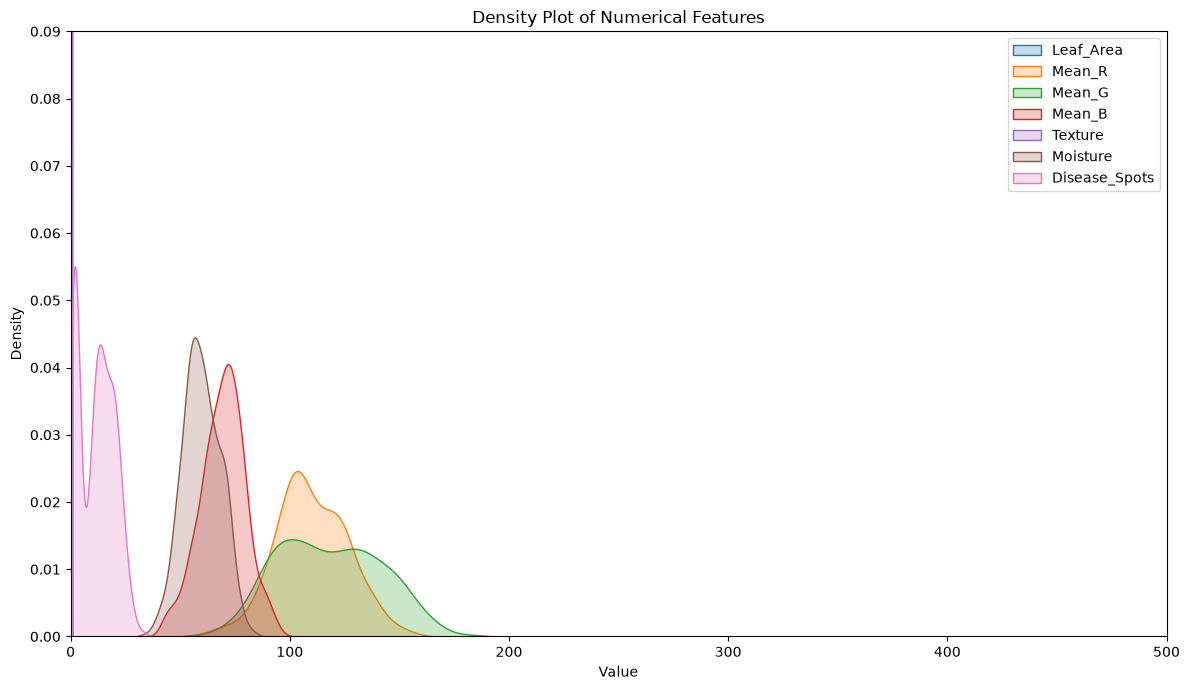

In [5]:
numeric_cols = ["Leaf_Area", "Mean_R", "Mean_G", "Mean_B", "Texture", "Moisture", "Disease_Spots"]

df[numeric_cols].hist(figsize=(12, 8), bins=20)
plt.suptitle("Feature Distributions")
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Disease")
plt.title("Disease Class Distribution")
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Crop")
plt.title("Crop Distribution")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="Disease", y="Disease_Spots")
plt.title("Disease Spots by Disease Type")
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 7))

for column in numeric_cols:          # <-- fixed here
    sns.kdeplot(
        data=df,
        x=column,
        fill=True,
        label=column
    )

plt.title("Density Plot of Numerical Features")
plt.xlabel("Value")
plt.ylabel("Density")
plt.xlim(0, 500)   # Adjust based on your data range
plt.ylim(0, 0.09)  # Adjust based on your data range
plt.legend()
plt.tight_layout()
plt.show()

## 6. Correlation

C:\Users\user\AppData\Local\Temp\ipykernel_33072\2502165330.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df_encoded.select_dtypes(include="object").columns:


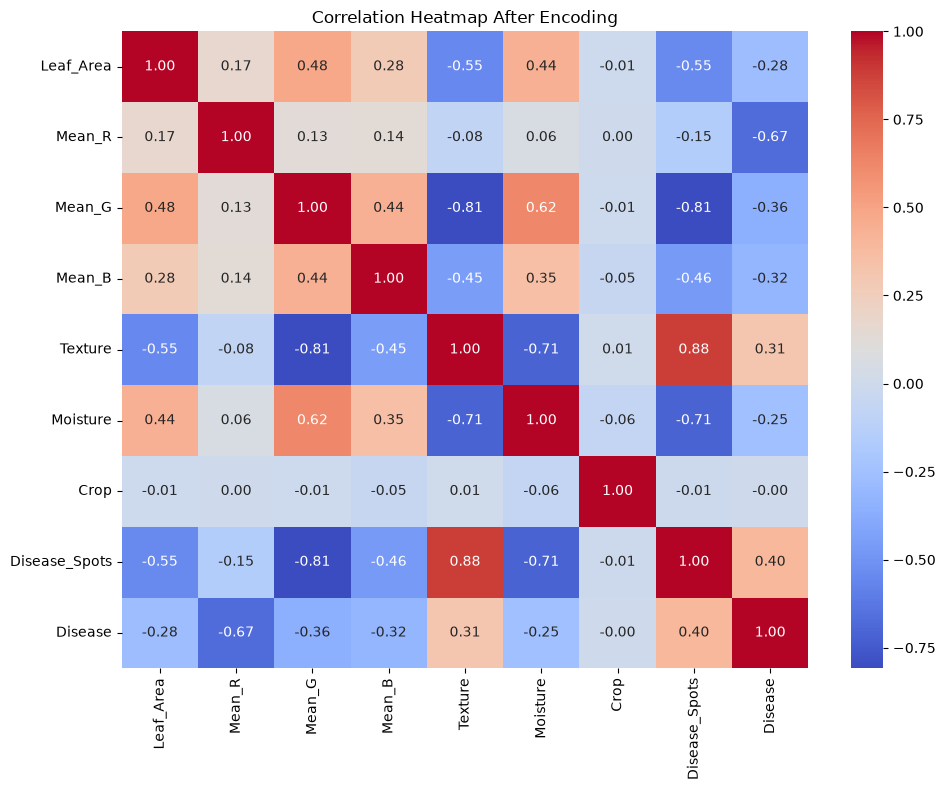

In [6]:
df_encoded = df.copy()
for col in df_encoded.select_dtypes(include="object").columns:
    df_encoded[col] = LabelEncoder().fit_transform(df_encoded[col])

plt.figure(figsize=(10, 8))
sns.heatmap(
    df_encoded.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Heatmap After Encoding")
plt.tight_layout()
plt.show()

## 7. Preprocessing (Encoding + MinMaxScaler)

In [7]:
crop_encoder = LabelEncoder()
disease_encoder = LabelEncoder()

df["Crop"] = crop_encoder.fit_transform(df["Crop"])
df["Disease"] = disease_encoder.fit_transform(df["Disease"])

X = df.drop("Disease", axis=1)
y = df["Disease"]

scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X)

print("Features scaled. Shape:", X_scaled.shape)

Features scaled. Shape: (600, 8)


## 8. Train/Test Split

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (480, 8)
Testing data: (120, 8)


## 9. Decision Tree

Decision Tree Accuracy: 96.67 %

Classification Report:
              precision    recall  f1-score   support

Early_Blight       0.95      0.95      0.95        40
     Healthy       1.00      1.00      1.00        40
 Late_Blight       0.95      0.95      0.95        40

    accuracy                           0.97       120
   macro avg       0.97      0.97      0.97       120
weighted avg       0.97      0.97      0.97       120



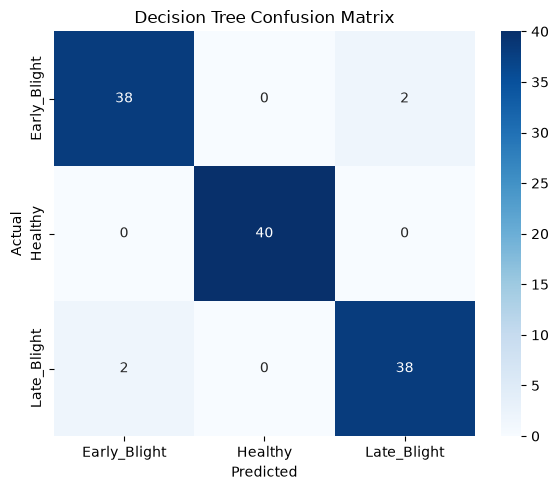

In [9]:
dt_model = DecisionTreeClassifier(criterion="gini", max_depth=10, random_state=42)
dt_model.fit(X_train, y_train)

dt_pred = dt_model.predict(X_test)
dt_accuracy = accuracy_score(y_test, dt_pred)

print("Decision Tree Accuracy:", round(dt_accuracy * 100, 2), "%")
print("\nClassification Report:")
print(classification_report(y_test, dt_pred, target_names=disease_encoder.classes_))

dt_cm = confusion_matrix(y_test, dt_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(dt_cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=disease_encoder.classes_, yticklabels=disease_encoder.classes_)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Decision Tree Confusion Matrix")
plt.tight_layout()
plt.show()

## 10. Random Forest

Random Forest Accuracy: 99.17 %

Classification Report:
              precision    recall  f1-score   support

Early_Blight       0.98      1.00      0.99        40
     Healthy       1.00      1.00      1.00        40
 Late_Blight       1.00      0.97      0.99        40

    accuracy                           0.99       120
   macro avg       0.99      0.99      0.99       120
weighted avg       0.99      0.99      0.99       120



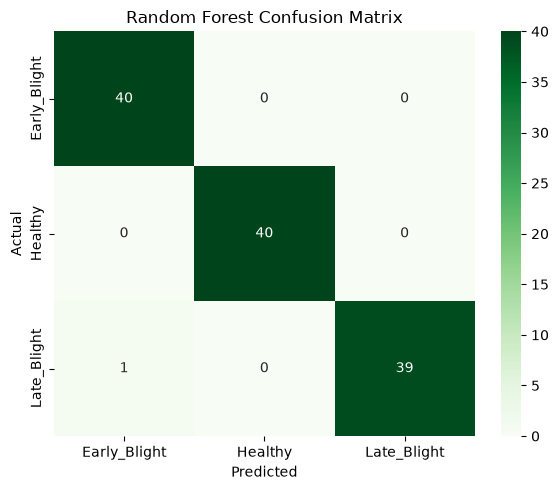

In [10]:
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)
rf_accuracy = accuracy_score(y_test, rf_pred)

print("Random Forest Accuracy:", round(rf_accuracy * 100, 2), "%")
print("\nClassification Report:")
print(classification_report(y_test, rf_pred, target_names=disease_encoder.classes_))

rf_cm = confusion_matrix(y_test, rf_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(rf_cm, annot=True, fmt="d", cmap="Greens",
            xticklabels=disease_encoder.classes_, yticklabels=disease_encoder.classes_)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest Confusion Matrix")
plt.tight_layout()
plt.show()

## 11. Model Comparison

------------------------------------
MODEL ACCURACY COMPARISON
------------------------------------
Decision Tree Accuracy: 96.67 %
Random Forest Accuracy: 99.17 %


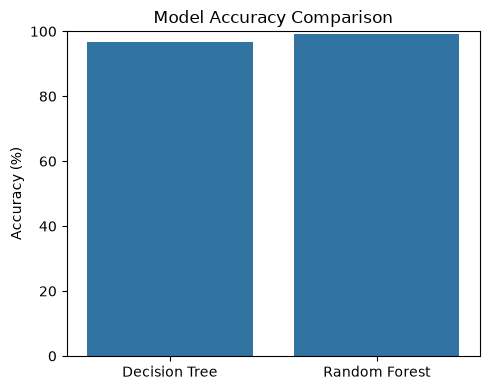


Selected Model for Prediction: Random Forest


In [11]:
print("------------------------------------")
print("MODEL ACCURACY COMPARISON")
print("------------------------------------")
print("Decision Tree Accuracy:", round(dt_accuracy * 100, 2), "%")
print("Random Forest Accuracy:", round(rf_accuracy * 100, 2), "%")

plt.figure(figsize=(5, 4))
sns.barplot(x=["Decision Tree", "Random Forest"], y=[dt_accuracy * 100, rf_accuracy * 100])
plt.ylabel("Accuracy (%)")
plt.title("Model Accuracy Comparison")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

if rf_accuracy >= dt_accuracy:
    best_model = rf_model
    selected_model_name = "Random Forest"
else:
    best_model = dt_model
    selected_model_name = "Decision Tree"

print("\nSelected Model for Prediction:", selected_model_name)

## 12. Prediction (User Input)

In [12]:
print("------------------------------------")
print("ENTER LEAF INFORMATION")
print("------------------------------------")

crop = input("Enter Crop (Potato/Tomato): ").strip().capitalize()
leaf_area = float(input("Enter Leaf Area: "))
mean_r = float(input("Enter Mean R: "))
mean_g = float(input("Enter Mean G: "))
mean_b = float(input("Enter Mean B: "))
texture = float(input("Enter Texture (0-1): "))
moisture = float(input("Enter Moisture: "))
disease_spots = float(input("Enter Disease Spots: "))

if crop not in crop_encoder.classes_:
    raise ValueError(
        f"'{crop}' is not a known crop. Valid options are: {list(crop_encoder.classes_)}"
    )

crop_encoded = crop_encoder.transform([crop])[0]

user_data = pd.DataFrame(
    [[leaf_area, mean_r, mean_g, mean_b, texture, moisture, crop_encoded, disease_spots]],
    columns=X.columns
)

user_data_scaled = scaler.transform(user_data)

dt_result = disease_encoder.inverse_transform(dt_model.predict(user_data_scaled))[0]
rf_result = disease_encoder.inverse_transform(rf_model.predict(user_data_scaled))[0]
rf_confidence = max(rf_model.predict_proba(user_data_scaled)[0]) * 100

print("\n------------------------------------")
print("PREDICTION RESULTS")
print("------------------------------------")
print("Decision Tree Prediction:", dt_result)
print("Random Forest Prediction:", rf_result)
print("Random Forest Confidence:", round(rf_confidence, 2), "%")

print("\n------------------------------------")
print("MODEL COMPARISON")
print("------------------------------------")
if dt_result == rf_result:
    print("Both models give the same prediction.")
else:
    print("The models give different predictions.")

final_prediction = rf_result if selected_model_name == "Random Forest" else dt_result

print("\n------------------------------------")
print("FINAL RESULT")
print("------------------------------------")
print("Selected Model:", selected_model_name)
print("Predicted Disease:", final_prediction)

------------------------------------
ENTER LEAF INFORMATION
------------------------------------

------------------------------------
PREDICTION RESULTS
------------------------------------
Decision Tree Prediction: Early_Blight
Random Forest Prediction: Healthy
Random Forest Confidence: 35.0 %

------------------------------------
MODEL COMPARISON
------------------------------------
The models give different predictions.

------------------------------------
FINAL RESULT
------------------------------------
Selected Model: Random Forest
Predicted Disease: Healthy
